In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def design_matrix(X):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1: X = X.reshape(-1, 1)
    return np.column_stack((np.ones(len(X)), X))

def standardise(X_train, X_other):
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0, ddof=0)
    sigma = np.where(sigma == 0, 1., sigma)
    return (X_train-mu)/sigma, (X_other-mu)/sigma, mu, sigma

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return np.exp(-np.logaddexp(0., -z))

def fit_logistic(X, y, lr=0.1, max_iter=30000, tol=1e-10):
    """Batch gradient descent, averaged BCE gradient; X includes intercept."""
    X, y = np.asarray(X, float), np.asarray(y, float)
    w = np.zeros(X.shape[1]); history=[]
    for i in range(max_iter):
        p = sigmoid(X @ w)
        grad = X.T @ (p-y)/len(y)
        new_w = w - lr*grad
        if i % 100 == 0:
            loss = np.mean(np.logaddexp(0, X @ new_w)-y*(X @ new_w))
            history.append(loss)
        if np.max(np.abs(new_w-w)) < tol:
            w=new_w; break
        w=new_w
    return w, np.asarray(history)

def confusion_matrix_scratch(y_true, y_pred):
    y_true=np.asarray(y_true); y_pred=np.asarray(y_pred)
    tn=int(np.sum((y_true==0)&(y_pred==0)))
    fp=int(np.sum((y_true==0)&(y_pred==1)))
    fn=int(np.sum((y_true==1)&(y_pred==0)))
    tp=int(np.sum((y_true==1)&(y_pred==1)))
    return np.array([[tn,fp],[fn,tp]])

def classification_metrics(y_true, y_pred):
    tn,fp,fn,tp=confusion_matrix_scratch(y_true,y_pred).ravel()
    safe=lambda a,b: a/b if b else 0.
    precision=safe(tp,tp+fp); recall=safe(tp,tp+fn)
    return dict(accuracy=safe(tp+tn,tp+tn+fp+fn), precision=precision,
                recall=recall, f1=safe(2*precision*recall,precision+recall))

def roc_curve_scratch(y_true, y_score):
    """Thresholds include +inf; group tied scores to produce valid ROC points."""
    y_true=np.asarray(y_true,int); y_score=np.asarray(y_score,float)
    if len(y_true)!=len(y_score) or not np.all(np.isfinite(y_score)):
        raise ValueError('Scores must be finite and aligned with labels.')
    P=np.sum(y_true==1); N=np.sum(y_true==0)
    if P==0 or N==0: raise ValueError('ROC needs both classes.')
    order=np.argsort(-y_score,kind='mergesort')
    ys=y_true[order]; ss=y_score[order]
    last=np.r_[np.flatnonzero(np.diff(ss)),len(ss)-1]
    tp=np.cumsum(ys==1)[last]; fp=np.cumsum(ys==0)[last]
    return np.r_[0,fp/N],np.r_[0,tp/P],np.r_[np.inf,ss[last]]

def auc_trapezoid(fpr,tpr):
    fpr=np.asarray(fpr,float);tpr=np.asarray(tpr,float)
    if np.any(np.diff(fpr)<0): raise ValueError('FPR must be sorted ascending')
    return float(np.sum(np.diff(fpr)*(tpr[1:]+tpr[:-1])/2))

path=Path('ic272_lab8_loans.csv')
if not path.exists():
    raise FileNotFoundError('Place ic272_lab8_loans.csv in the same folder as this notebook, then Run All.')
df=pd.read_csv(path)
required={'income_k','utilisation','employment','defaulted'}
if not required.issubset(df.columns): raise ValueError(f'Missing columns: {required-set(df.columns)}')
X=df[['income_k','utilisation']].to_numpy(float)
emp=df['employment'].to_numpy()
y=df['defaulted'].to_numpy(int)
assert set(np.unique(y))=={0,1}, 'Expected binary labels 0 and 1.'
idx=np.random.default_rng(0).permutation(len(y))
te,tr=idx[:100],idx[100:]
X_train,y_train,emp_train=X[tr],y[tr],emp[tr]
X_test,y_test,emp_test=X[te],y[te],emp[te]
print('Train/test:',len(tr),len(te)); print('Employment categories:',pd.unique(emp))

Train/test: 400 100
Employment categories: ['salaried' 'student' 'self_employed' 'retired']


In [3]:
def gaussian_pdf(x, mu, var):
    var=np.maximum(np.asarray(var,float),1e-12)
    return np.exp(-0.5*(np.asarray(x)-mu)**2/var)/np.sqrt(2*np.pi*var)

def fit_gaussian_nb(X,y):
    X=np.asarray(X,float); y=np.asarray(y,int)
    classes=np.array([0,1])
    counts=np.array([np.sum(y==c) for c in classes])
    if np.any(counts==0): raise ValueError('Both classes must occur in training data.')
    priors=counts/len(y)
    means=np.vstack([X[y==c].mean(axis=0) for c in classes])
    variances=np.vstack([X[y==c].var(axis=0,ddof=0) for c in classes])
    return priors,means,np.maximum(variances,1e-12)

# Lecture sanity check: equal class priors and heights.
example_X=np.array([160,170,165,150,155,145],float).reshape(-1,1)
example_y=np.array([0,0,0,1,1,1])
ep,em,ev=fit_gaussian_nb(example_X,example_y)
pa=float(gaussian_pdf(162,em[0,0],ev[0,0])); pb=float(gaussian_pdf(162,em[1,0],ev[1,0]))
posterior_a=pa*ep[0]/(pa*ep[0]+pb*ep[1])
print('Lecture check P(162|A), P(162|B), P(A|162):',pa,pb,posterior_a)
assert np.isclose(pa,0.0746,atol=0.001)
assert np.isclose(pb,0.0013,atol=0.001)
assert posterior_a>0.97
priors,means,variances=fit_gaussian_nb(X_train,y_train)
print('Class priors [0,1]:',priors)
print('Means (rows=classes, columns=income_k/utilisation):\n',means)
print('Variances (rows=classes, columns=income_k/utilisation):\n',variances)
assert priors.shape==(2,) and means.shape==variances.shape==(2,2)

Lecture check P(162|A), P(162|B), P(A|162): 0.07459782769363346 0.001299671301370867 0.9828759666842724
Class priors [0,1]: [0.7425 0.2575]
Means (rows=classes, columns=income_k/utilisation):
 [[77.66329966  0.38854209]
 [53.77864078  0.58560194]]
Variances (rows=classes, columns=income_k/utilisation):
 [[1.81430003e+03 3.21900462e-02]
 [1.03564498e+03 3.57098901e-02]]


In [4]:
def nb_log_scores(X,priors,means,variances):
    X=np.asarray(X,float)
    if X.ndim==1: X=X.reshape(1,-1)
    v=np.maximum(variances,1e-12)
    return np.log(priors)[None,:]-0.5*np.sum(
        np.log(2*np.pi*v)[None,:,:]+(X[:,None,:]-means[None,:,:])**2/v[None,:,:],axis=2)

def predict_proba_nb(X,priors,means,variances):
    L=nb_log_scores(X,priors,means,variances)
    return sigmoid(L[:,1]-L[:,0])

nb_prob=predict_proba_nb(X_test,priors,means,variances)
nb_pred=(nb_prob>=0.5).astype(int)
print('Confusion matrix [[TN,FP],[FN,TP]]:\n',confusion_matrix_scratch(y_test,nb_pred))
print(pd.Series(classification_metrics(y_test,nb_pred)).to_string())
assert np.all((nb_prob>=0)&(nb_prob<=1))

Confusion matrix [[TN,FP],[FN,TP]]:
 [[63  7]
 [11 19]]
accuracy     0.820000
precision    0.730769
recall       0.633333
f1           0.678571


Logistic weights (intercept, income_k, utilisation): [-1.59396339 -1.13311055  1.3476339 ]
Gaussian NB AUC: 0.88762 Logistic AUC: 0.89571
Higher test AUC: Logistic regression


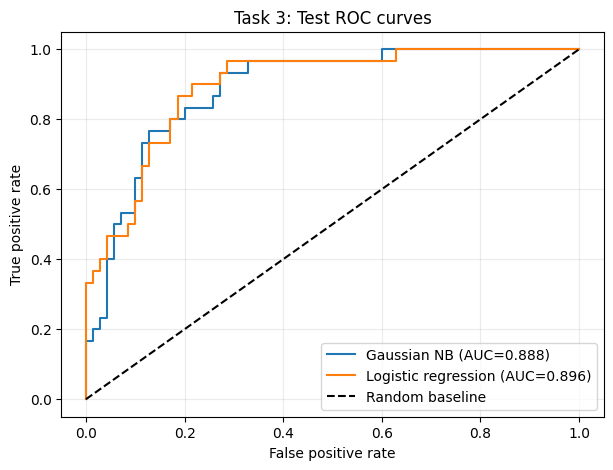

In [5]:
Xtr_s,Xte_s,train_mu,train_sd=standardise(X_train,X_test)
w,loss_history=fit_logistic(design_matrix(Xtr_s),y_train)
log_prob=sigmoid(design_matrix(Xte_s)@w)
nb_fpr,nb_tpr,_=roc_curve_scratch(y_test,nb_prob)
lr_fpr,lr_tpr,_=roc_curve_scratch(y_test,log_prob)
nb_auc=auc_trapezoid(nb_fpr,nb_tpr)
lr_auc=auc_trapezoid(lr_fpr,lr_tpr)
print('Logistic weights (intercept, income_k, utilisation):',w)
print('Gaussian NB AUC:',round(nb_auc,5),'Logistic AUC:',round(lr_auc,5))
print('Higher test AUC:', 'Gaussian NB' if nb_auc>lr_auc else 'Logistic regression' if lr_auc>nb_auc else 'Tie')
plt.figure(figsize=(7,5))
plt.plot(nb_fpr,nb_tpr,label=f'Gaussian NB (AUC={nb_auc:.3f})')
plt.plot(lr_fpr,lr_tpr,label=f'Logistic regression (AUC={lr_auc:.3f})')
plt.plot([0,1],[0,1],'k--',label='Random baseline')
plt.xlabel('False positive rate');plt.ylabel('True positive rate')
plt.title('Task 3: Test ROC curves');plt.legend();plt.grid(alpha=.25);plt.show()

In [6]:
categories=np.sort(pd.unique(emp))
assert len(categories)==4, f'Expected 4 employment categories; found {categories}'

def fit_categorical_nb(e,y,l):
    e=np.asarray(e);y=np.asarray(y,int)
    if l<0: raise ValueError('Smoothing must be nonnegative.')
    table=np.zeros((2,len(categories)),float)
    for c in (0,1):
        ec=e[y==c]; counts=np.array([np.sum(ec==cat) for cat in categories])
        table[c]=(counts+l)/(len(ec)+l*len(categories))
    return table

cat0=fit_categorical_nb(emp_train,y_train,0)
cat1=fit_categorical_nb(emp_train,y_train,1)
print('Categories:',categories)
print('lambda=0:\n',pd.DataFrame(cat0,index=['class 0','class 1'],columns=categories))
print('lambda=1:\n',pd.DataFrame(cat1,index=['class 0','class 1'],columns=categories))
print('Zero-count class/category pairs:',[(c,str(categories[j])) for c,j in np.argwhere(cat0==0)])
assert np.allclose(cat0.sum(axis=1),1) and np.allclose(cat1.sum(axis=1),1)

Categories: ['retired' 'salaried' 'self_employed' 'student']
lambda=0:
           retired  salaried  self_employed   student
class 0  0.074074  0.572391       0.222222  0.131313
class 1  0.184466  0.388350       0.427184  0.000000
lambda=1:
           retired  salaried  self_employed   student
class 0  0.076412  0.568106       0.222591  0.132890
class 1  0.186916  0.383178       0.420561  0.009346
Zero-count class/category pairs: [(np.int64(1), 'student')]


In [7]:
cat_to_idx={cat:i for i,cat in enumerate(categories)}
def predict_proba_combined(X,e,priors,means,variances,cat_table):
    e=np.asarray(e)
    ids=np.array([cat_to_idx[v] for v in e])
    L=nb_log_scores(X,priors,means,variances)
    with np.errstate(divide='ignore'):
        L=L+np.log(cat_table[:,ids].T)
    normalizer=np.logaddexp(L[:,0],L[:,1])
    if np.any(~np.isfinite(normalizer)):
        raise ValueError('Both classes assigned zero likelihood; use Laplace smoothing.')
    return np.exp(L[:,1]-normalizer)

combined0=predict_proba_combined(X_test,emp_test,priors,means,variances,cat0)
combined1=predict_proba_combined(X_test,emp_test,priors,means,variances,cat1)
student_mask=np.array([str(v).strip().lower() in ('student','students') for v in emp_test])
mask=student_mask&(y_test==1)
print('Test applicants who are students and defaulted:',int(mask.sum()))
print(pd.DataFrame({'test_row':np.flatnonzero(mask),'numeric_only':nb_prob[mask],
                    'combined_lambda_0':combined0[mask], 'combined_lambda_1':combined1[mask]}).to_string(index=False))
print(pd.DataFrame({'model':['Numeric only','Combined lambda=0','Combined lambda=1'],
                    'AUC':[auc_trapezoid(*roc_curve_scratch(y_test,p)[:2]) for p in (nb_prob,combined0,combined1)]}).to_string(index=False))

Test applicants who are students and defaulted: 3
 test_row  numeric_only  combined_lambda_0  combined_lambda_1
        1      0.684969                0.0           0.132631
       28      0.403703                0.0           0.045449
       42      0.479240                0.0           0.060786
            model      AUC
     Numeric only 0.887619
Combined lambda=0 0.834286
Combined lambda=1 0.871905


In [8]:
Xtr_dup=np.column_stack([X_train[:,0],X_train[:,1],X_train[:,1],X_train[:,1]])
Xte_dup=np.column_stack([X_test[:,0],X_test[:,1],X_test[:,1],X_test[:,1]])
dp,dm,dv=fit_gaussian_nb(Xtr_dup,y_train)
dup_prob=predict_proba_nb(Xte_dup,dp,dm,dv)
def extreme_fraction(p): return np.mean((p>0.99)|(p<0.01))
print(pd.DataFrame({'model':['Original NB','Repeated utilisation NB'],
 'AUC':[nb_auc,auc_trapezoid(*roc_curve_scratch(y_test,dup_prob)[:2])],
 'fraction P<0.01 or P>0.99':[extreme_fraction(nb_prob),extreme_fraction(dup_prob)]}).to_string(index=False))

                  model      AUC  fraction P<0.01 or P>0.99
            Original NB 0.887619                       0.05
Repeated utilisation NB 0.863810                       0.38


AttributeError: 'QuadContourSet' object has no attribute 'collections'

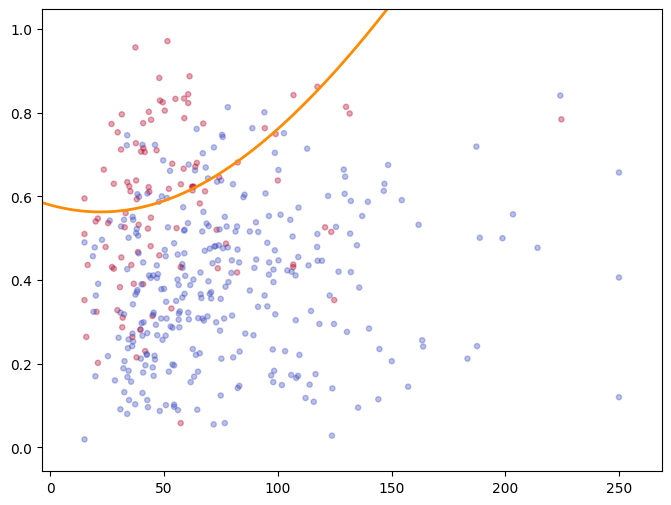

In [9]:
margin=np.ptp(X_train,axis=0)*0.08
lo=X_train.min(axis=0)-margin; hi=X_train.max(axis=0)+margin
g1,g2=np.meshgrid(np.linspace(lo[0],hi[0],250),np.linspace(lo[1],hi[1],250))
grid=np.column_stack((g1.ravel(),g2.ravel()))
ng=predict_proba_nb(grid,priors,means,variances).reshape(g1.shape)
lg=sigmoid(design_matrix((grid-train_mu)/train_sd)@w).reshape(g1.shape)
fig,ax=plt.subplots(figsize=(8,6))
ax.scatter(X_train[:,0],X_train[:,1],c=y_train,cmap='coolwarm',s=14,alpha=.35)
for surface,color,label in [(ng,'darkorange','Gaussian NB p=0.5'),(lg,'black','Logistic p=0.5')]:
    if surface.min()<=0.5<=surface.max():
        contour=ax.contour(g1,g2,surface,levels=[.5],colors=[color],linewidths=2)
        contour.collections[0].set_label(label)
    else: print(label,'does not cross plotted grid')
ax.set(xlabel='income_k',ylabel='utilisation',title='H4: Decision boundaries')
ax.legend();ax.grid(alpha=.2);plt.show()
print('Class-specific feature variances:\n',pd.DataFrame(variances,index=['class 0','class 1'],columns=['income_k','utilisation']))